In [8]:
%load_ext autoreload
%autoreload 2
%reset -f
%matplotlib widget

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [9]:
import sys
from pathlib import Path
import pandas as pd
from lib.config import PEAKMIN_CONFIG_PARAMS_DEFAULT, FLOWRATE_CONFIG_PARAMS_DEFAULT
r2 = Path.cwd()  # keep notebook kernel cwd on Challenge_SystemHealthAlarm/r2
sys.path.insert(0, str(r2.parents[2] / "packages"))
sys.path.insert(0, str(r2))

from lib.Detector.FlowrateDetector import *
from lib.Detector.PeakMinDetector import *
from lib.Detector.FaultDetector import *

from lib.SurveyorLookup import get_latest_customer_per_surveyor_unit
import matplotlib.pyplot as plt

surveyor_lookup = get_latest_customer_per_surveyor_unit()
i = 150
customer_id = surveyor_lookup['CustomerId'].iloc[i]
surveyor_unit_id = surveyor_lookup['SurveyorUnitId'].iloc[i]
surveyor_unit = surveyor_lookup['SurveyorUnit'].iloc[i]
customer_name = surveyor_lookup['CustomerName'].iloc[i]
print(customer_id, surveyor_unit_id, surveyor_unit, customer_name)
flowrate_detector = FlowRateDetector()
flowrate_detector.set_surveyor_unit(customer_id=customer_id, surveyor_unit_id=surveyor_unit_id)
flowrate_detector.load_data()
flowrate_detector.load_config()
flowrate_detector.run_detector(write_back=True)

D70A7F5E-5A7C-AFD3-CB50-39FEB47BD8FC F0DA1676-E53B-0B96-88EA-3A08E0A19A4F GEI spa Car #2 GEI spa
0
No data to run detector FlowRateDetector


In [10]:
flowrate_detector.sandbox_data

,CustomerId,CustomerName,SurveyorUnit,SurveyorUnitId,SurveyId,AnalyzerSerialNumber,StartDateTime,EndDateTime,AverageFlowRate,PeakCount,...,FlowrateDx,FlowrateDelta,FlowrateAlpha,FlowrateBeta,FlowrateI,FlowRateC,FlowrateH,FlowRateFlag,FlowRateNStep,LastUpdate
0,D70A7F5E-5A7C-AFD3-CB50-39FEB47BD8FC,GEI spa,GEI spa Car #2,F0DA1676-E53B-0B96-88EA-3A08E0A19A4F,24690833-AA20-14A9-D2B0-3A21705BCDAE,RFADS2425,2026-05-25 08:10:07.703000,2026-05-25 11:25:12.557000,4.257003,56.0,...,0.000000,0.0,0.00,0.00,0.0,0.0,0.0,0,0,2026-11-16 14:21:00.026529
1,D70A7F5E-5A7C-AFD3-CB50-39FEB47BD8FC,GEI spa,GEI spa Car #2,F0DA1676-E53B-0B96-88EA-3A08E0A19A4F,6C5D38CD-DD91-0A67-18D9-3A21710EFF33,RFADS2425,2026-05-25 11:25:41.363000,2026-05-25 12:19:11.183000,4.195107,20.0,...,-0.061896,0.0,0.01,0.01,0.0,0.0,0.0,0,0,2026-11-16 14:21:00.028479
2,D70A7F5E-5A7C-AFD3-CB50-39FEB47BD8FC,GEI spa,GEI spa Car #2,F0DA1676-E53B-0B96-88EA-3A08E0A19A4F,094130C2-4B60-4A9C-8695-3A2171405C40,RFADS2425,2026-05-25 12:19:37.070000,2026-05-25 13:58:49.660000,4.204613,31.0,...,0.009506,0.0,0.01,0.01,0.0,0.0,0.0,0,0,2026-11-16 14:21:00.030201


In [11]:
peak_detector = PeakMinDetector()
peak_detector.set_surveyor_unit(customer_id=customer_id, surveyor_unit_id=surveyor_unit_id)
peak_detector.load_data()
peak_detector.load_config()
peak_detector.run_detector(write_back=True)


0
No data to run detector PeakMinDetector


In [12]:
detector_list = [flowrate_detector, peak_detector]
fault_detector = FaultDetector()
fault_detector.set_surveyor_unit(customer_id=customer_id, surveyor_unit_id=surveyor_unit_id)
fault_detector.load_data()
fault_detector.load_config()
fault_detector.sandbox_data
fault_detector.run_detector(write_back=True)


0
0
No data to run detector FaultDetector


In [13]:
fault_detector.survey_data

,CustomerId,CustomerName,SurveyorUnit,SurveyorUnitId,SurveyId,AnalyzerSerialNumber,StartDateTime,EndDateTime,AverageFlowRate,PeakCount,PeakMinutes,RawDurationMinutes,RetrivedDate
0,D70A7F5E-5A7C-AFD3-CB50-39FEB47BD8FC,GEI spa,GEI spa Car #2,F0DA1676-E53B-0B96-88EA-3A08E0A19A4F,24690833-AA20-14A9-D2B0-3A21705BCDAE,RFADS2425,2026-05-25 08:10:07.703000,2026-05-25 11:25:12.557000,4.257003,56.0,0.287179,195.0,2026-11-11 14:43:06.316588
1,D70A7F5E-5A7C-AFD3-CB50-39FEB47BD8FC,GEI spa,GEI spa Car #2,F0DA1676-E53B-0B96-88EA-3A08E0A19A4F,6C5D38CD-DD91-0A67-18D9-3A21710EFF33,RFADS2425,2026-05-25 11:25:41.363000,2026-05-25 12:19:11.183000,4.195107,20.0,0.370370,54.0,2026-11-11 14:43:06.316588
2,D70A7F5E-5A7C-AFD3-CB50-39FEB47BD8FC,GEI spa,GEI spa Car #2,F0DA1676-E53B-0B96-88EA-3A08E0A19A4F,094130C2-4B60-4A9C-8695-3A2171405C40,RFADS2425,2026-05-25 12:19:37.070000,2026-05-25 13:58:49.660000,4.204613,31.0,0.313131,99.0,2026-11-11 14:43:06.316588


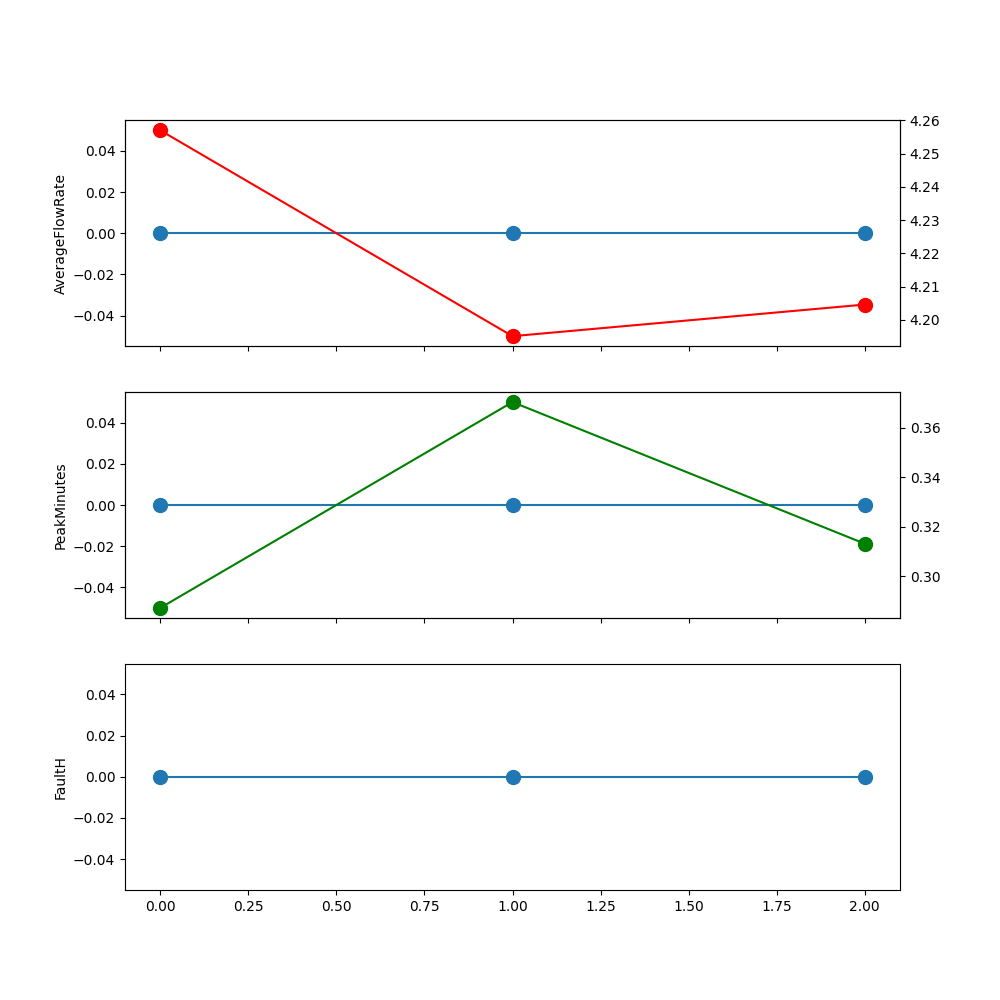

In [14]:
fig,ax = plt.subplots(3,1, sharex=True, figsize=(10,10))
ax[0].plot(flowrate_detector.sandbox_data["FlowrateH"], marker='o', markersize=10)
ax[0].set_ylabel("FlowrateH")
ax00 =ax[0].twinx()
ax00.plot(flowrate_detector.sandbox_data["AverageFlowRate"], marker='o', markersize=10, color='red')
ax[0].set_ylabel("AverageFlowRate")

ax[1].plot(peak_detector.sandbox_data["PeakH"], marker='o', markersize=10)
ax[1].set_ylabel("PeakH")
ax10 = ax[1].twinx()
ax10.plot(peak_detector.sandbox_data["PeakMinutes"], marker='o', markersize=10, color='green')
ax[1].set_ylabel("PeakMinutes")
ax[2].plot(fault_detector.sandbox_data["FaultH"], marker='o', markersize=10)
ax[2].set_ylabel("FaultH")
plt.show()